In [26]:
# import pandas 
import pandas as pd  

# import numpy
import numpy as np 

# import matplotlib
from matplotlib import pyplot as plt  

# make plots appear and be stored within the notebook
%matplotlib inline  

In [28]:
import pandas as pd

met = pd.read_csv(r"D:\python class\ESE5023_Assignments_12632710\Assignment 02\earthquakes-2026-10-14_20-32-06_+0800.tsv",sep="\t")
met.head(500)
met.info()
met.columns
met.head()
met.head(10)
met.tail()
met.tail(10)
# 删除文件中不是地震记录的查询参数行
Sig_Eqs = met.dropna(subset=["Id"]).copy()

<class 'pandas.DataFrame'>
RangeIndex: 6698 entries, 0 to 6697
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Search Parameters                   1 non-null      str    
 1   Id                                  6697 non-null   float64
 2   Year                                6697 non-null   float64
 3   Mo                                  6293 non-null   float64
 4   Dy                                  6122 non-null   float64
 5   Hr                                  4580 non-null   float64
 6   Mn                                  4357 non-null   float64
 7   Sec                                 3864 non-null   float64
 8   Tsu                                 2124 non-null   float64
 9   Vol                                 82 non-null     float64
 10  Country                             6697 non-null   str    
 11  Area                                335 non-null    st

In [3]:
#1.1
deaths = Sig_Eqs.groupby("Country")["Deaths"].sum(min_count=1)
print(deaths.sort_values(ascending=False).head(20))


Country
CHINA           2139209.0
TURKEY          1199720.0
IRAN            1014453.0
ITALY            492236.0
SYRIA            419826.0
HAITI            323484.0
AZERBAIJAN       319251.0
JAPAN            242516.0
ARMENIA          177890.0
PAKISTAN         145085.0
IRAQ             136200.0
ECUADOR          135496.0
TURKMENISTAN     117412.0
PERU             102309.0
ISRAEL            93388.0
PORTUGAL          83572.0
GREECE            81162.0
CHILE             64277.0
INDIA             63507.0
TAIWAN            57154.0
Name: Deaths, dtype: float64


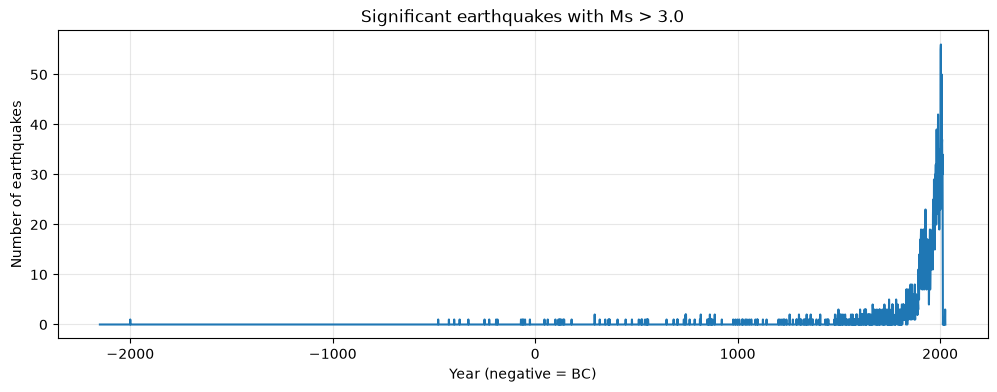

In [15]:
#1.2
counts = Sig_Eqs[Sig_Eqs["Ms"] > 3.0].groupby("Year").size()
# 补齐没有符合条件记录的年份
years = range(int(Sig_Eqs["Year"].min()), int(Sig_Eqs["Year"].max()) + 1)
counts = counts.reindex(years, fill_value=0).drop(0)
counts.plot(figsize=(12, 4))
plt.xlabel("Year (negative = BC)")
plt.ylabel("Number of earthquakes")
plt.title("Significant earthquakes with Ms > 3.0")
plt.grid(alpha=0.3)
plt.show()

In [16]:
#1.3
def CountEq_LargestEq(country):
    data = Sig_Eqs[Sig_Eqs["Country"] == country]
    largest = data[data["Mag"] == data["Mag"].max()]
#筛选属于这个国家的全部地震记录。找到该国最大的主震级 Mag、
    #然后筛选震级等于这个最大值的记录。如果有多次地震并列最大，就全部保留。
    return len(data), largest[["Year", "Mo", "Dy", "Location Name", "Mag"]]
#如果该国震级全部缺失，第二个结果为空，表示无法确定最大地震
#统计每个国家出现的次数。value_counts() 默认按次数从大到小排序
countries = Sig_Eqs["Country"].value_counts()

for country in countries.index:
    count, largest = CountEq_LargestEq(country)
    print(f"\n{country}: {count} earthquakes")
    print(largest.to_string(index=False))


CHINA: 626 earthquakes
  Year  Mo   Dy             Location Name  Mag
1668.0 7.0 25.0 CHINA:  SHANDONG PROVINCE  8.5

JAPAN: 429 earthquakes
  Year  Mo   Dy  Location Name  Mag
2011.0 3.0 11.0 JAPAN:  HONSHU  9.1

INDONESIA: 427 earthquakes
  Year   Mo   Dy                               Location Name  Mag
2004.0 12.0 26.0 INDONESIA:  SUMATRA:  ACEH:  OFF WEST COAST  9.1

IRAN: 385 earthquakes
 Year   Mo   Dy         Location Name  Mag
856.0 12.0 22.0 IRAN:  DAMGHAN, QUMIS  7.9

TURKEY: 359 earthquakes
  Year   Mo   Dy                Location Name  Mag
1939.0 12.0 26.0            TURKEY:  ERZINCAN  7.8
2023.0  2.0  6.0 TURKEY: KAHRAMANMARAS; SYRIA  7.8

ITALY: 338 earthquakes
  Year  Mo   Dy                      Location Name  Mag
1915.0 1.0 13.0 ITALY:  MARSICA, AVEZZANO, ABRUZZI  7.5

GREECE: 296 earthquakes
  Year  Mo   Dy            Location Name  Mag
 365.0 7.0 21.0 GREECE:  CRETE:  KNOSSOS  8.0
1303.0 8.0  8.0           GREECE:  CRETE  8.0

USA: 283 earthquakes
  Year  Mo   Dy Lo

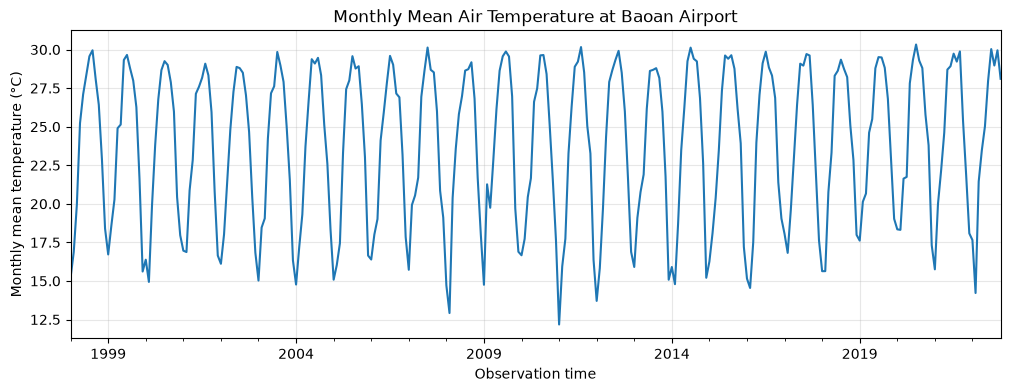

In [9]:
#2
import pandas as pd
import matplotlib.pyplot as pltSD

met = pd.read_csv(
    r"D:\python class\ESE5023_Assignments_12632710\Assignment 02\Baoan_Weather_1998_2022.csv",
    usecols=["DATE", "TMP"]
)
met["DATE"] = pd.to_datetime(met["DATE"])

# 拆分温度编码和质量标记
tmp = met["TMP"].str.split(",", expand=True)
met["Temperature"] = pd.to_numeric(tmp[0], errors="coerce")

# 保留通过全部质量检查、且不是缺失值的温度
met = met[tmp[1].isin(["1", "5"]) & met["Temperature"].ne(9999)].copy()

# 转换为摄氏度
met["Temperature"] = met["Temperature"] / 10

# 先计算小时平均，再计算月平均
hourly = met.set_index("DATE")["Temperature"].resample("h").mean()
monthly = hourly.resample("MS").mean()

# 绘图
monthly.plot(figsize=(12, 4))
plt.xlabel("Observation time")
plt.ylabel("Monthly mean temperature (°C)")
plt.title("Monthly Mean Air Temperature at Baoan Airport")
plt.grid(alpha=0.3)
plt.show()

In [10]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    r"D:\python class\ESE5023_Assignments_12632710\Assignment 02\ibtracs.ALL.list.v04r00.csv",
    usecols=range(17),
    skiprows=[1],
    parse_dates=["ISO_TIME"],
    skipinitialspace=True,
    keep_default_na=False,
    na_values=["", " ", "NOT_NAMED", "NAME"],
    low_memory=False
)

# 确保风速、经纬度为数字
for col in ["WMO_WIND", "LAT", "LON"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.head()

,SID,SEASON,NUMBER,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,WMO_WIND,WMO_PRES,WMO_AGENCY,TRACK_TYPE,DIST2LAND,LANDFALL,IFLAG
0,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 03:00:00,NR,10.9000,80.3000,NaN,NaN,NaN,main,43,0.0,__________O___
1,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 06:00:00,NR,10.8709,79.8265,NaN,NaN,NaN,main,0,0.0,__________P___
2,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 09:00:00,NR,10.8431,79.3524,NaN,NaN,NaN,main,0,0.0,__________P___
3,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 12:00:00,NR,10.8188,78.8772,NaN,NaN,NaN,main,0,0.0,__________P___
4,1842298N11080,1842,1,NI,BB,NaN,1842-10-25 15:00:00,NR,10.8000,78.4000,NaN,NaN,NaN,main,0,0.0,__________O___


In [11]:
#3.1
storms = df.groupby("SID").agg(
    NAME=("NAME", "first"),
    WMO_WIND=("WMO_WIND", "max")
)

top10 = storms.nlargest(10, "WMO_WIND")
print(top10)

                   NAME  WMO_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
1935241N23291       NaN     160.0
1988253N12306   GILBERT     160.0
1997253N12255     LINDA     160.0
2005289N18282     WILMA     160.0
2019236N10314    DORIAN     160.0
1998295N12284     MITCH     155.0
2005261N21290      RITA     155.0
2009288N07267      RICK     155.0


In [12]:
#3.2
top20 = storms.nlargest(20, "WMO_WIND")
print(top20)

                   NAME  WMO_WIND
SID                              
2015293N13266  PATRICIA     185.0
1980214N11330     ALLEN     165.0
1935241N23291       NaN     160.0
1988253N12306   GILBERT     160.0
1997253N12255     LINDA     160.0
2005289N18282     WILMA     160.0
2019236N10314    DORIAN     160.0
1998295N12284     MITCH     155.0
2005261N21290      RITA     155.0
2009288N07267      RICK     155.0
2017242N16333      IRMA     155.0
1932304N15305       NaN     150.0
1955265N13307     JANET     150.0
1959249N19181     PATSY     150.0
1969226N18280   CAMILLE     150.0
1977242N27272     ANITA     150.0
1979238N12324     DAVID     150.0
1992230N11325    ANDREW     150.0
1994222N11267      JOHN     150.0
2005236N23285   KATRINA     150.0


In [13]:
#3.3
#统计每个海盆代码出现的行数
basin_counts = df["BASIN"].value_counts()
print(basin_counts)

BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55402
SA       119
Name: count, dtype: int64


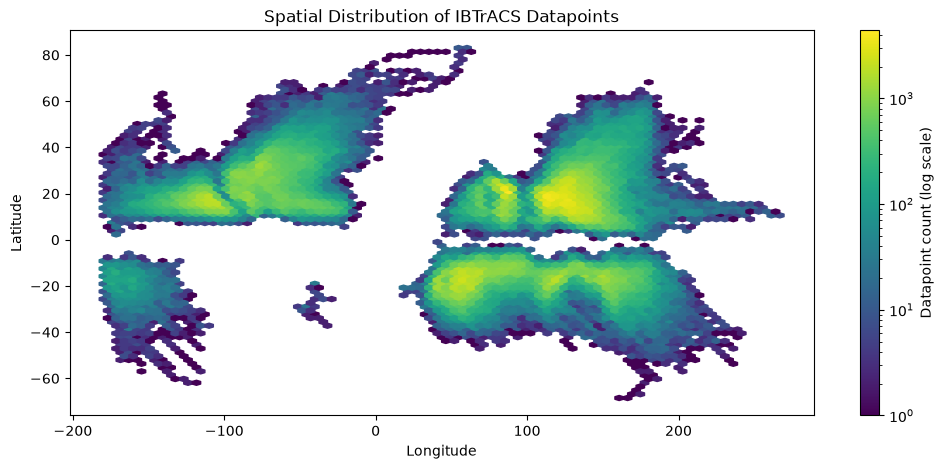

In [14]:
#3.4
positions = df.dropna(subset=["LAT", "LON"])
#bins="log" 使用对数颜色刻度，便于同时看清密集和稀疏区域；mincnt=1 隐藏没有观测点的格子。
#hexbin() 将空间划分成六边形，颜色表示每格的观测点数量。横轴使用经度，纵轴使用纬度。
plt.figure(figsize=(12, 5))
plt.hexbin(
    positions["LON"], positions["LAT"],
    gridsize=80, bins="log", mincnt=1,
    cmap="viridis"
)
plt.colorbar(label="Datapoint count (log scale)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Spatial Distribution of IBTrACS Datapoints")
plt.show()

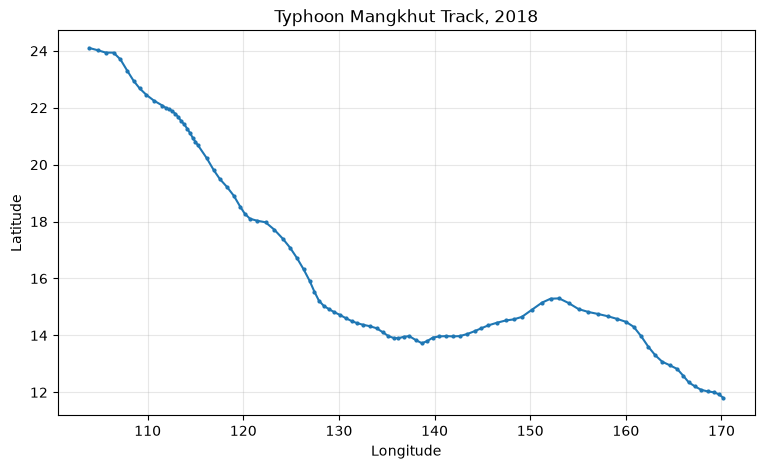

In [15]:
#3.5
mangkhut = df[
    (df["NAME"] == "MANGKHUT") &
    (df["SEASON"] == 2018)
].sort_values("ISO_TIME")

plt.figure(figsize=(9, 5))
plt.plot(mangkhut["LON"], mangkhut["LAT"], "-o", markersize=2)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Typhoon Mangkhut Track, 2018")
plt.grid(alpha=0.3)
plt.show()

In [16]:
#3.6
#两个条件必须同时满足：
#观测时间不早于1970年1月1日。
#海盆属于 WP 或 EP。用 .isin() 判断是否属于指定海盆
    (df["ISO_TIME"] >= "1970-01-01") &
    df["BASIN"].isin(["WP", "EP"])
].copy()

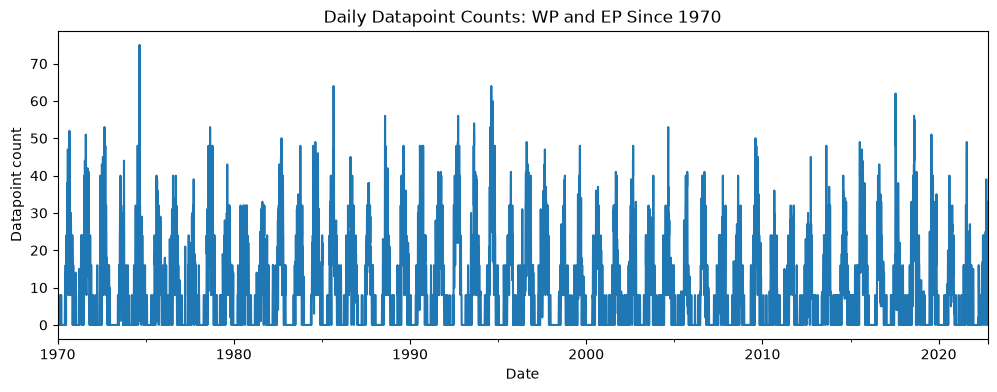

In [17]:
#3.7
#先把时间设为索引，再用 resample("D").size() 统计每天的行数
daily = filtered.set_index("ISO_TIME").resample("D").size()

dates = pd.date_range(
    "1970-01-01",
    filtered["ISO_TIME"].max().normalize(),
    freq="D"
)
daily = daily.reindex(dates, fill_value=0)

daily.plot(figsize=(12, 4))
plt.xlabel("Date")
plt.ylabel("Datapoint count")
plt.title("Daily Datapoint Counts: WP and EP Since 1970")
plt.show()

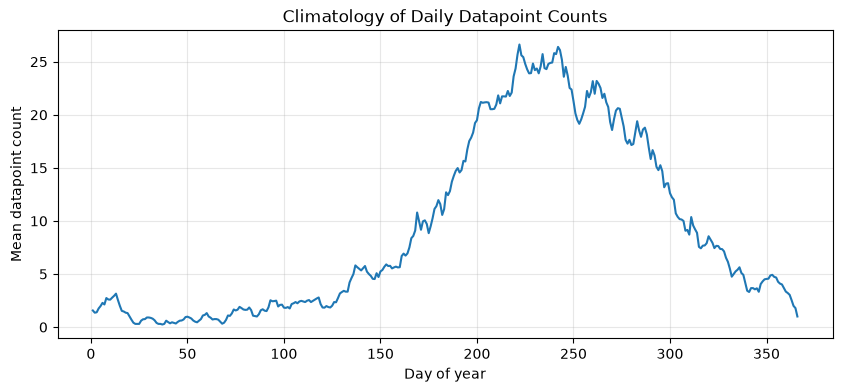

In [18]:
#3.8
climatology = daily.groupby(daily.index.dayofyear).mean()

climatology.plot(figsize=(10, 4))
plt.xlabel("Day of year")
plt.ylabel("Mean datapoint count")
plt.title("Climatology of Daily Datapoint Counts")
plt.grid(alpha=0.3)
plt.show()

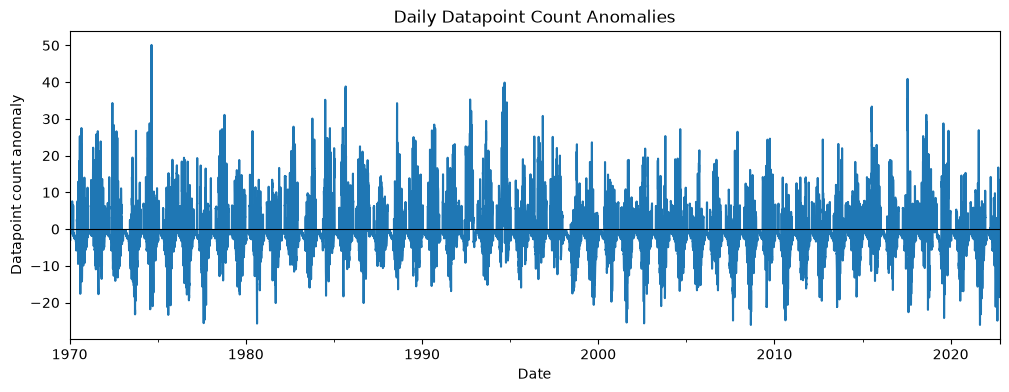

In [19]:
#3.9
#使用 .map(climatology) 为每天找到相应的气候态值，再相减。.to_numpy() 让两组数按位置相减
#避免日期索引与日序索引不一致。
expected = daily.index.dayofyear.map(climatology).to_numpy()
anomaly = daily - expected

anomaly.plot(figsize=(12, 4))
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Date")
plt.ylabel("Datapoint count anomaly")
plt.title("Daily Datapoint Count Anomalies")
plt.show()

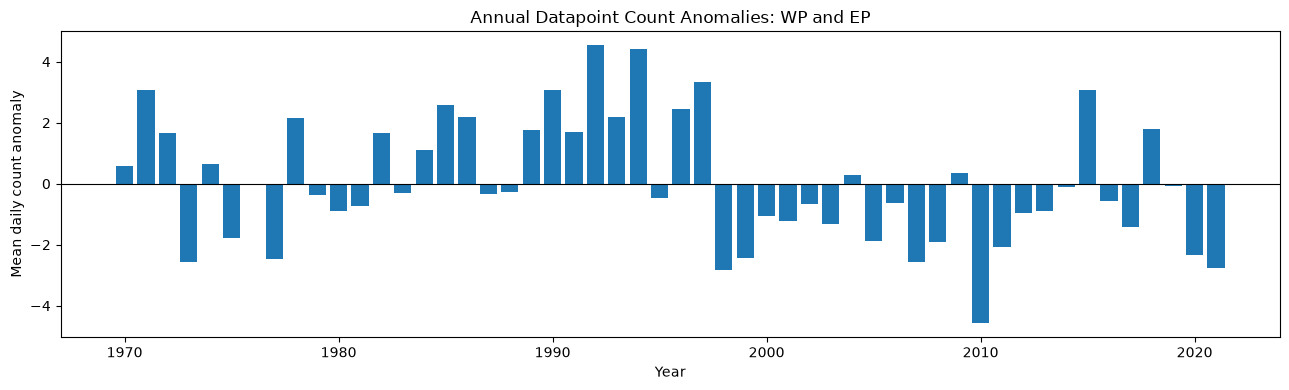

Highest positive anomalies:
1992    4.540
1994    4.419
1997    3.334
1990    3.076
2015    3.071
dtype: float64

Lowest negative anomalies:
2010   -4.568
1998   -2.828
2021   -2.748
2007   -2.559
1973   -2.554
dtype: float64


In [22]:
#3.10
# 计算年度平均异常
annual_anomaly = anomaly.resample("YS").mean()

# 只比较完整年份，排除不完整的2022年
complete_years = annual_anomaly.loc["1970":"2021"].copy()

# 将日期索引转为整数年份，避免绘图时的频率转换问题
complete_years.index = complete_years.index.year

# 使用 matplotlib 绘制柱状图
plt.figure(figsize=(13, 4))
plt.bar(complete_years.index, complete_years.values)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Year")
plt.ylabel("Mean daily count anomaly")
plt.title("Annual Datapoint Count Anomalies: WP and EP")
plt.tight_layout()
plt.show()

print("Highest positive anomalies:")
print(complete_years.nlargest(5).round(3))

print("\nLowest negative anomalies:")
print(complete_years.nsmallest(5).round(3))

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
#4.1
data = pd.read_csv(r"D:\python class\ESE5023_Assignments_12632710\Assignment 02\global_temperature_1850_2025.csv",
    comment="#",
    na_values=[-999, -999.9, -999.99, -9999]
)

data.columns = ["Year", "Anomaly"]

# 转为数字，无法转换的内容设为缺失值
for col in data.columns:
    data[col] = pd.to_numeric(data[col], errors="coerce")

print("Missing values:")
print(data.isna().sum())

# 删除缺失值和重复记录，按年份排序
data = data.dropna().drop_duplicates().sort_values("Year")
data["Year"] = data["Year"].astype(int)

print(data.head())

Missing values:
Year       0
Anomaly    0
dtype: int64
   Year  Anomaly
0  1850    -0.15
1  1851    -0.06
2  1852    -0.03
3  1853    -0.07
4  1854    -0.05


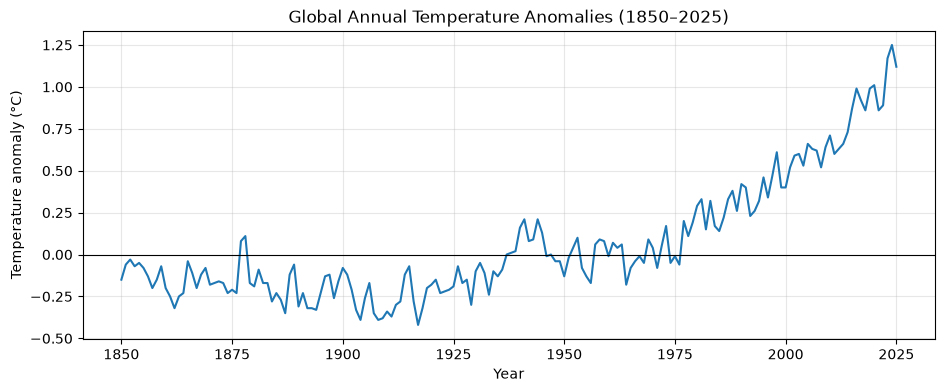

In [24]:
#4.2
plt.figure(figsize=(11, 4))

plt.plot(data["Year"], data["Anomaly"])
plt.axhline(0, color="black", linewidth=0.8)

plt.xlabel("Year")
plt.ylabel("Temperature anomaly (°C)")
plt.title("Global Annual Temperature Anomalies (1850–2025)")
plt.grid(alpha=0.3)

plt.show()

In [25]:
#4.3
# 样本数、均值、标准差、最小值、分位数、最大值
print(data["Anomaly"].describe().round(3))

# 最大值对应年份
print("\nWarmest year:")
print(data.loc[data["Anomaly"].idxmax()])

# 最小值对应年份
print("\nColdest year:")
print(data.loc[data["Anomaly"].idxmin()])

# 线性变化趋势
slope, intercept = np.polyfit(data["Year"], data["Anomaly"], 1)

print("\nTrend (°C per decade):", round(slope * 10, 3))

count    176.000
mean       0.063
std        0.361
min       -0.420
25%       -0.180
50%       -0.060
75%        0.210
max        1.250
Name: Anomaly, dtype: float64

Warmest year:
Year       2024.00
Anomaly       1.25
Name: 174, dtype: float64

Coldest year:
Year       1917.00
Anomaly      -0.42
Name: 67, dtype: float64

Trend (°C per decade): 0.057
